In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import json
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import jax
import jax.numpy as jnp
from sklearn.decomposition import PCA

from network import LeakyRNN
from task import generate_trials, load_params as load_task_params
from utils.fixed_points import find_fixed_points, get_phase_step, phase_label
%matplotlib widget

In [2]:
# ── Checkpoint to analyse ─────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
ckpt_path = RESULTS_DIR / 'pure/pure_0_lr5e-05_bs128_noise0.5_nrnn128/checkpoint.pkl'
task_type = 'pure'
task_list = ['pure', 'harmonic', 'wn']

# ── Trial phases to search for fixed points ───────────────────────────────────
# Each entry: (phase, pulse_num)
#   phase      : 'fixation' | 'stim_on' | 'stim_off' | 'pulse_on'
#   pulse_num  : 1-indexed pulse number (only used for 'pulse_on')
#
# 'fixation'   — last pre-stim step (fixation=1, no stimulus, context on)
# 'stim_on'    — stimulus onset (fixation off, pulse 1 starts)
# 'stim_off'   — end of stimulus (silence resumes)
# 'pulse_on'   — during the N-th pulse, input held constant
phases = [
    ('fixation',  None),
    ('stim_off',  None),
    ('pulse_on',   1),
    ('pulse_on',   2),
    ('pulse_on',   3),
    ('pulse_on',   4),
    ('pulse_on',   5),
    ('pulse_on',   6),
    ('pulse_on',   7),
    ('pulse_on',   8),
]

# ── Fixed-point optimisation settings ────────────────────────────────────────
n_trials   = 256   # number of test trials (initial hidden states per condition)
n_iters    = 24000  # Adam steps
lr         = 1e-2  # Adam learning rate
tol        = 1e-6 # q-value threshold for convergence
unique_tol = 1e-3  # L2 distance for deduplication

In [3]:
# ── Load config.json for model/task hyperparameters ───────────────────────────
with open(ckpt_path.parent / 'config.json') as f:
    config = json.load(f)

hp          = config['training']
task_params = config['task_params']
# 'task_list' in modern configs (main & transfer); 'tasks' in old format
task_list   = config.get('task_list', config.get('tasks', task_list))
# 'train_task' in main training config; 'task_type' in transfer config
task_type   = config.get('train_task', config.get('task_type', task_type))

# ── Load checkpoint for params and timing ─────────────────────────────────────
with open(ckpt_path, 'rb') as f:
    ckpt = pickle.load(f)

params = ckpt['params']

# Timing: prefer values stored directly in checkpoint, fall back to task_params
dt          = ckpt.get('dt',       task_params['timing']['dt'])
stim_on     = ckpt.get('stim_on',  config.get('stim_on',
                         int(task_params['timing']['pre_stim_dur_ms'] / dt)))
stim_off    = ckpt.get('stim_off', config.get('stim_off',
                         stim_on + task_params['timing']['n_pulses'] *
                         max(1, int(np.ceil(task_params['timing']['pulse_dur_ms'] / dt)))))
pulse_steps = config.get('pulse_steps',
              max(1, int(np.ceil(task_params['timing']['pulse_dur_ms'] / dt))))

n_rnn = hp['model']['n_rnn']
alpha = dt / hp['model']['tau']

print(f'Loaded: {ckpt_path}  (step {ckpt["step"]})')
print(f'n_rnn={n_rnn}  tau={hp["model"]["tau"]}ms  alpha={alpha:.3f}')
print(f'stim_on={stim_on}  stim_off={stim_off}  pulse_steps={pulse_steps}  dt={dt}ms')
print(f'task_type={task_type}  task_list={task_list}')

# ── Run model on test trials (no noise) to get hidden-state trajectories ──────
model = LeakyRNN(
    n_rnn     = n_rnn,
    n_out     = 1,
    alpha     = alpha,
    sigma_rec = hp['model']['sigma_rec'],
    sigma_x   = hp['model']['sigma_x'],
)

trial = generate_trials(task_type, task_list, mode='test',
                        batch_size=n_trials, rng=np.random.default_rng(1))
xs    = jnp.array(trial.x)
_, hs_jax = model.apply({'params': params}, xs,
                         noise_input=False, noise_rec=False,
                         rngs={'noise': jax.random.PRNGKey(0)})
hs = np.array(hs_jax)   # (tdim, batch, n_rnn)

go_mask   = trial.is_go
nogo_mask = ~trial.is_go
print(f'Trials: {go_mask.sum()} Go, {nogo_mask.sum()} No-Go')

out_dir = ckpt_path.parent / f'checkpoint_{ckpt["step"]}'
out_dir.mkdir(exist_ok=True)
print(f'Output dir: {out_dir}')

Loaded: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint.pkl  (step 15000)
n_rnn=128  tau=100ms  alpha=0.100
stim_on=50  stim_off=90  pulse_steps=5  dt=10ms
task_type=pure  task_list=['pure', 'harmonic', 'wn']
Trials: 128 Go, 128 No-Go
Output dir: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000


In [4]:
# ── Find fixed points at each phase for Go and No-Go conditions ───────────────
# Phases where the stimulus is active — fixation is forced to 1 in frozen input
STIM_ON_PHASES = {'stim_on', 'pulse_on'}
# 'fixation': trial.x already has fixation=1 and no stimulus — no override needed
# 'stim_off': silence, fixation stays 0 — no override needed

results = {}

for phase, pulse_num in phases:
    t_step = get_phase_step(phase, stim_on, stim_off, pulse_steps,
                            pulse_num=pulse_num if pulse_num else 2)
    key = phase_label(phase, pulse_num)
    print(f'\n══ {key}  (t={t_step}) ══')

    # Frozen input: take from the first trial of each condition
    # (within a condition the input is deterministic, so one trial suffices)
    x_go   = trial.x[t_step, np.where(go_mask)[0][0],   :].copy() if go_mask.any()   else None
    x_nogo = trial.x[t_step, np.where(nogo_mask)[0][0], :].copy() if nogo_mask.any() else None

    # During stimulus-on phases, force fixation=1 (channel n_freq)
    if phase in STIM_ON_PHASES:
        n_freq = trial.n_freq
        if x_go   is not None: x_go[n_freq]   = 1.0
        if x_nogo is not None: x_nogo[n_freq] = 1.0

    # Initial hidden states at this timestep
    h_go   = hs[t_step, go_mask,   :]
    h_nogo = hs[t_step, nogo_mask, :]

    cond_results = {}
    for cond, x_frozen, h_inits in [('go', x_go, h_go), ('nogo', x_nogo, h_nogo)]:
        if x_frozen is None:
            continue
        print(f'  [{cond}]  {len(h_inits)} initial states')
        cond_results[cond] = find_fixed_points(
            params, x_frozen, h_inits, alpha,
            n_iters=n_iters, lr=lr, tol=tol, unique_tol=unique_tol,
            verbose=True)

    results[key] = {
        'conds':  cond_results,
        't_step': t_step,
        'x_go':   x_go,
        'x_nogo': x_nogo,
        'h_go':   h_go,
        'h_nogo': h_nogo,
    }

print('\nDone.')


══ fixation  (t=49) ══
  [go]  128 initial states
    iter  500  min_q=1.59e-04  converged=0/128
    iter 1000  min_q=7.61e-06  converged=0/128
    iter 1500  min_q=5.40e-06  converged=0/128
    iter 2000  min_q=4.73e-06  converged=0/128
    iter 2500  min_q=4.04e-06  converged=0/128
    iter 3000  min_q=3.34e-06  converged=0/128
    iter 3500  min_q=2.69e-06  converged=0/128
    iter 4000  min_q=1.57e-06  converged=0/128
    iter 4500  min_q=1.90e-07  converged=128/128
    iter 5000  min_q=8.62e-08  converged=128/128
    iter 5500  min_q=3.59e-08  converged=128/128
    iter 6000  min_q=1.13e-08  converged=128/128
    iter 6500  min_q=2.58e-09  converged=128/128
    iter 7000  min_q=3.87e-10  converged=128/128
    iter 7500  min_q=5.25e-11  converged=128/128
    iter 8000  min_q=1.69e-12  converged=128/128
    iter 8500  min_q=8.73e-12  converged=128/128
    iter 9000  min_q=4.57e-12  converged=128/128
    iter 9500  min_q=8.82e-10  converged=128/128
    iter 10000  min_q=1.40e-11  co

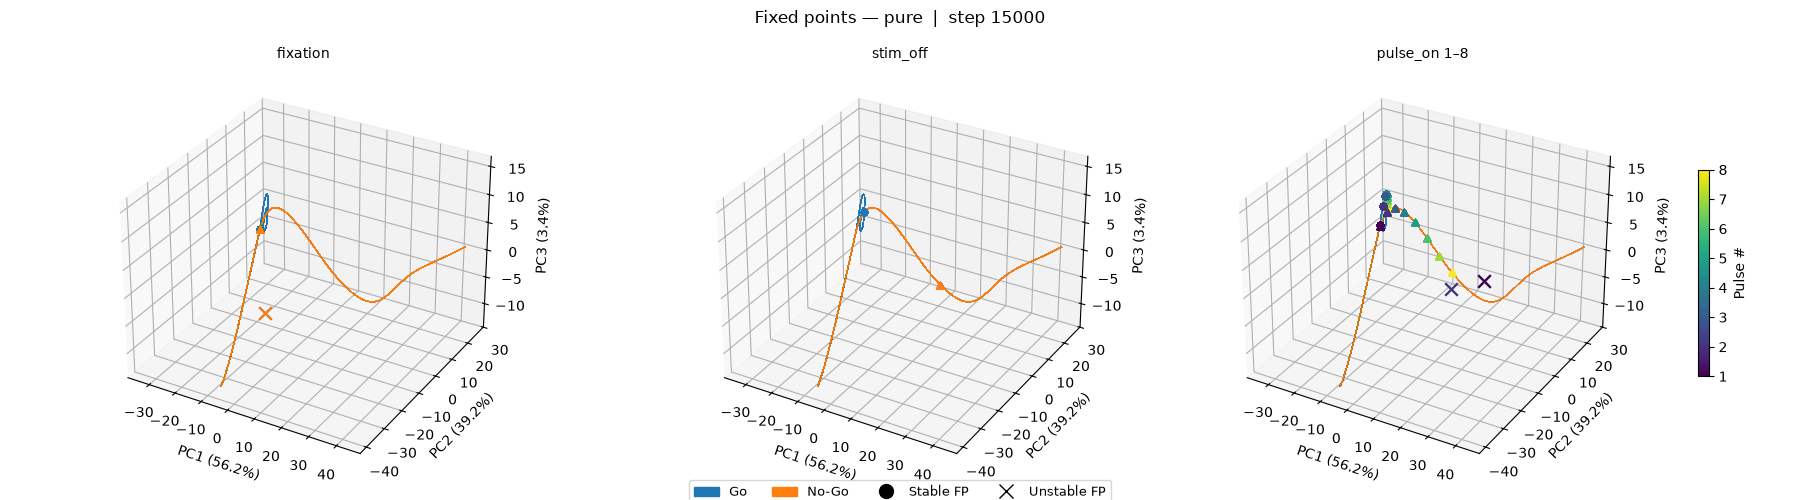

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000/fixed_points.png


In [5]:
# ── PCA projection: fixed points + network trajectories (3D) ──────────────────
hs_flat = hs.reshape(-1, hs.shape[-1])
pca     = PCA(n_components=3)
pca.fit(hs_flat)
var_exp = pca.explained_variance_ratio_ * 100

COND_MKR     = {'go': 'o', 'nogo': '^'}
STABLE_MKR   = 'o'
UNSTABLE_MKR = 'x'

# Separate pulse_on results from others
pulse_results = {k: v for k, v in results.items() if k.startswith('pulse_on')}
other_results = {k: v for k, v in results.items() if not k.startswith('pulse_on')}
n_pulses = len(pulse_results)

n_cols = len(other_results) + (1 if pulse_results else 0)
fig = plt.figure(figsize=(6 * n_cols, 5))

def _draw_traj(ax, alpha=0.12, lw=0.7):
    for i in np.where(go_mask)[0]:
        p = pca.transform(hs[:, i, :])
        ax.plot(p[:, 0], p[:, 1], p[:, 2], color='tab:blue', alpha=alpha, lw=lw)
    for i in np.where(nogo_mask)[0]:
        p = pca.transform(hs[:, i, :])
        ax.plot(p[:, 0], p[:, 1], p[:, 2], color='tab:orange', alpha=alpha, lw=lw)

def _scatter_fp(ax, px, py, pz, stable, color):
    if stable:
        ax.scatter(px, py, pz, s=120, marker=STABLE_MKR,
                   color=color, edgecolors='black', linewidths=0.8, depthshade=False)
    else:
        ax.scatter(px, py, pz, s=80, marker=UNSTABLE_MKR,
                   color=color, depthshade=False)

def _set_labels(ax, title):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
    ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=4)

# ── Individual subplots for non-pulse phases ──────────────────────────────────
for col, (key, res) in enumerate(other_results.items()):
    ax = fig.add_subplot(1, n_cols, col + 1, projection='3d')
    _draw_traj(ax)
    t_step = res['t_step']

    for cond, mask, color in [('go',   go_mask,   'tab:blue'),
                               ('nogo', nogo_mask, 'tab:orange')]:
        p = pca.transform(hs[t_step, mask, :])
        ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=20, color=color,
                   alpha=0.6, marker=COND_MKR[cond], depthshade=False)

    for cond, color in [('go', 'tab:blue'), ('nogo', 'tab:orange')]:
        if cond not in res['conds']:
            continue
        fp = res['conds'][cond]
        if len(fp['h']) == 0:
            continue
        p = pca.transform(fp['h'])
        for (px, py, pz, stable) in zip(p[:, 0], p[:, 1], p[:, 2], fp['is_stable']):
            _scatter_fp(ax, px, py, pz, stable, color)

    _set_labels(ax, key)

# ── Combined pulse_on subplot with colormap ───────────────────────────────────
if pulse_results:
    ax   = fig.add_subplot(1, n_cols, n_cols, projection='3d')
    _draw_traj(ax, alpha=0.06)

    cmap = plt.cm.viridis
    norm = plt.Normalize(1, n_pulses)

    for pidx, (key, res) in enumerate(pulse_results.items()):
        color_p = cmap(norm(pidx + 1))
        t_step  = res['t_step']

        for cond, mask in [('go', go_mask), ('nogo', nogo_mask)]:
            p = pca.transform(hs[t_step, mask, :])
            ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=20, color=color_p,
                       alpha=0.6, marker=COND_MKR[cond], depthshade=False)

        for cond in ('go', 'nogo'):
            if cond not in res['conds']:
                continue
            fp = res['conds'][cond]
            if len(fp['h']) == 0:
                continue
            p = pca.transform(fp['h'])
            for (px, py, pz, stable) in zip(p[:, 0], p[:, 1], p[:, 2], fp['is_stable']):
                _scatter_fp(ax, px, py, pz, stable, color_p)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.12, label='Pulse #')
    cb.set_ticks(range(1, n_pulses + 1))

    _set_labels(ax, f'pulse_on 1–{n_pulses}')

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(color='tab:blue',   label='Go'),
    mpatches.Patch(color='tab:orange', label='No-Go'),
    plt.Line2D([0], [0], marker=STABLE_MKR,   color='k', linestyle='None',
               markersize=10, markeredgecolor='black', label='Stable FP'),
    plt.Line2D([0], [0], marker=UNSTABLE_MKR, color='k', linestyle='None',
               markersize=10, label='Unstable FP'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle(f'Fixed points — {task_type}  |  step {ckpt["step"]}', fontsize=12)
plt.tight_layout()
plt.savefig(out_dir / 'fixed_points.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_dir}/fixed_points.png')

In [ ]:
# ── PCA + k3d overview: trajectories + fixed points ───────────────────────────
import k3d
import matplotlib.colors as mcolors

def _k3d_color(c):
    r, g, b, *_ = mcolors.to_rgba(c)
    return (int(r * 255) << 16) | (int(g * 255) << 8) | int(b * 255)

GO_K3D      = _k3d_color('tab:blue')
NOGO_K3D    = _k3d_color('tab:orange')
MAX_TRAJ_OV = 32

def _add_traj(plot, opacity=0.15):
    for i in list(np.where(go_mask)[0])[:MAX_TRAJ_OV]:
        p = pca.transform(hs[:, i, :]).astype(np.float32)
        plot += k3d.line(p, color=GO_K3D, width=0.01, opacity=opacity, name='Go')
    for i in list(np.where(nogo_mask)[0])[:MAX_TRAJ_OV]:
        p = pca.transform(hs[:, i, :]).astype(np.float32)
        plot += k3d.line(p, color=NOGO_K3D, width=0.01, opacity=opacity, name='No-Go')

axis_labels = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', f'PC3 ({var_exp[2]:.1f}%)']

# ── One k3d plot per non-pulse phase ──────────────────────────────────────────
for key, res in other_results.items():
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = axis_labels
    _add_traj(plot)

    t_step = res['t_step']
    for cond, mask in [('go', go_mask), ('nogo', nogo_mask)]:
        col_c = GO_K3D if cond == 'go' else NOGO_K3D
        p = pca.transform(hs[t_step, mask, :]).astype(np.float32)
        plot += k3d.points(p, color=col_c, point_size=1, shader='3d',
                           opacity=0.7, name=f'{key} {cond}')
        if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
            fp     = res['conds'][cond]
            pfp    = pca.transform(fp['h']).astype(np.float32)
            stable = fp['is_stable']
            if stable.any():
                plot += k3d.points(pfp[stable], color=col_c, point_size=4,
                                   shader='3d', name=f'Stable FP {key} {cond}')
            if (~stable).any():
                plot += k3d.points(pfp[~stable], color=col_c, point_size=3,
                                   shader='flat', name=f'Unstable FP {key} {cond}')

    plot.display()
    fname = key.replace(' ', '_').replace('/', '-')
    out = out_dir / f'fp_overview_{fname}_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved [{key}]: {out}')

# ── Combined pulse_on plot (viridis by pulse #) ───────────────────────────────
if pulse_results:
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = axis_labels
    _add_traj(plot, opacity=0.06)

    cmap_vir = plt.cm.viridis
    norm_vir = plt.Normalize(1, max(len(pulse_results), 1))
    for pidx, (key, res) in enumerate(pulse_results.items()):
        col    = _k3d_color(cmap_vir(norm_vir(pidx + 1)))
        t_step = res['t_step']
        for cond, mask in [('go', go_mask), ('nogo', nogo_mask)]:
            p = pca.transform(hs[t_step, mask, :]).astype(np.float32)
            plot += k3d.points(p, color=col, point_size=1, shader='3d',
                               opacity=0.6, name=f'{key} {cond}')
            if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
                fp     = res['conds'][cond]
                pfp    = pca.transform(fp['h']).astype(np.float32)
                stable = fp['is_stable']
                if stable.any():
                    plot += k3d.points(pfp[stable], color=col, point_size=4,
                                       shader='3d', name=f'Stable FP {key}')
                if (~stable).any():
                    plot += k3d.points(pfp[~stable], color=col, point_size=3,
                                       shader='flat', name=f'Unstable FP {key}')

    plot.display()
    out = out_dir / f'fp_overview_pulses_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved [pulse_on 1-{len(pulse_results)}]: {out}')

Output()

Saved [fixation]: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fp_overview_fixation_15000.html


Output()

Saved [stim_off]: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fp_overview_stim_off_15000.html


Output()

Saved [pulse_on 1-8]: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fp_overview_pulses_15000.html


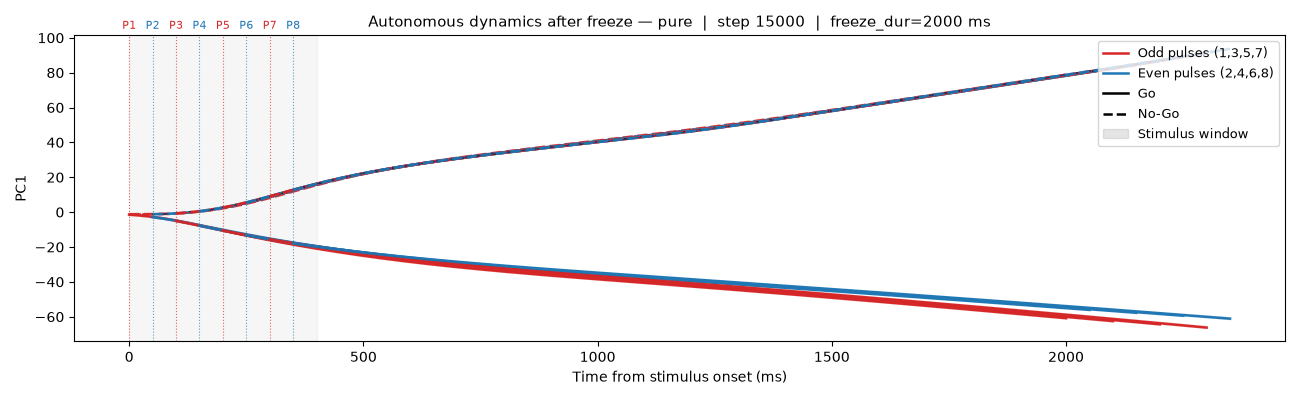

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_traj_15000.png


In [21]:
# ── Autonomous trajectories — all pulses in one plot, aligned to stim onset ───
freeze_dur_ms = 2000   # ← change this (ms)
n_auto = int(freeze_dur_ms / dt)

W_in  = np.array(params['W_in'])
W_rec = np.array(params['W_rec'])
b_rec = np.array(params['b_rec'])

def run_frozen(h0, x_frozen, n_steps):
    h = h0.astype(np.float32).copy()
    x = x_frozen.astype(np.float32)
    traj = [h.copy()]
    for _ in range(n_steps):
        pre = x @ W_in + h @ W_rec + b_rec
        h   = (1.0 - alpha) * h + alpha * np.maximum(0.0, pre)
        traj.append(h.copy())
    return np.stack(traj)   # (n_steps+1, batch, n_rnn)

points = [
    ('pulse_on', 1),
    ('pulse_on', 2),
    ('pulse_on', 3),
    ('pulse_on', 4),
    ('pulse_on', 5),
    ('pulse_on', 6),
    ('pulse_on', 7),
    ('pulse_on', 8),
]

# cmap/norm kept for downstream cells (b8b7f5c3, c6402543)
cmap = plt.cm.viridis
norm = plt.Normalize(1, len(points))

ODD_COLOR  = 'tab:red'   # pulses 1, 3, 5, 7
EVEN_COLOR = 'tab:blue'  # pulses 2, 4, 6, 8

fig, ax = plt.subplots(figsize=(13, 4))
xform = ax.get_xaxis_transform()   # x in data units, y in axes fraction

for pidx, (phase, pulse_num) in enumerate(points):
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue

    color = ODD_COLOR if pulse_num % 2 == 1 else EVEN_COLOR
    t_step       = res['t_step']
    t_offset_ms  = (t_step - stim_on) * dt
    t_axis_local = t_offset_ms + np.arange(n_auto + 1) * dt

    traj_go   = run_frozen(res['h_go'],   res['x_go'],   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], res['x_nogo'], n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]

    pc1_go   = pca.transform(traj_go.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_go_t)
    pc1_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_nogo_t)

    # Individual trials (very faint): go=solid, nogo=dashed
    for j in range(n_go_t):
        ax.plot(t_axis_local, pc1_go[:, j],   color=color, alpha=0.03, lw=0.6, ls='-')
    for j in range(n_nogo_t):
        ax.plot(t_axis_local, pc1_nogo[:, j], color=color, alpha=0.03, lw=0.6, ls='--')

    # Condition means
    ax.plot(t_axis_local, pc1_go.mean(1),   color=color, lw=2.0, ls='-',  alpha=0.9)
    ax.plot(t_axis_local, pc1_nogo.mean(1), color=color, lw=2.0, ls='--', alpha=0.9)

    # Freeze-point marker
    ax.axvline(t_offset_ms, color=color, lw=0.8, ls=':', alpha=0.7)
    ax.text(t_offset_ms, 1.02, f'P{pulse_num}', fontsize=8,
            ha='center', color=color, transform=xform)

# Stimulus window shading
ax.axvspan(0, (stim_off - stim_on) * dt, alpha=0.07, color='gray')

ax.set_xlabel('Time from stimulus onset (ms)')
ax.set_ylabel('PC1')

legend_handles = [
    plt.Line2D([0], [0], color=ODD_COLOR,  lw=1.8, label='Odd pulses (1,3,5,7)'),
    plt.Line2D([0], [0], color=EVEN_COLOR, lw=1.8, label='Even pulses (2,4,6,8)'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go'),
    mpatches.Patch(color='gray', alpha=0.2, label='Stimulus window'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper right')

ax.set_title(
    f'Autonomous dynamics after freeze — {task_type}  |  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_traj_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

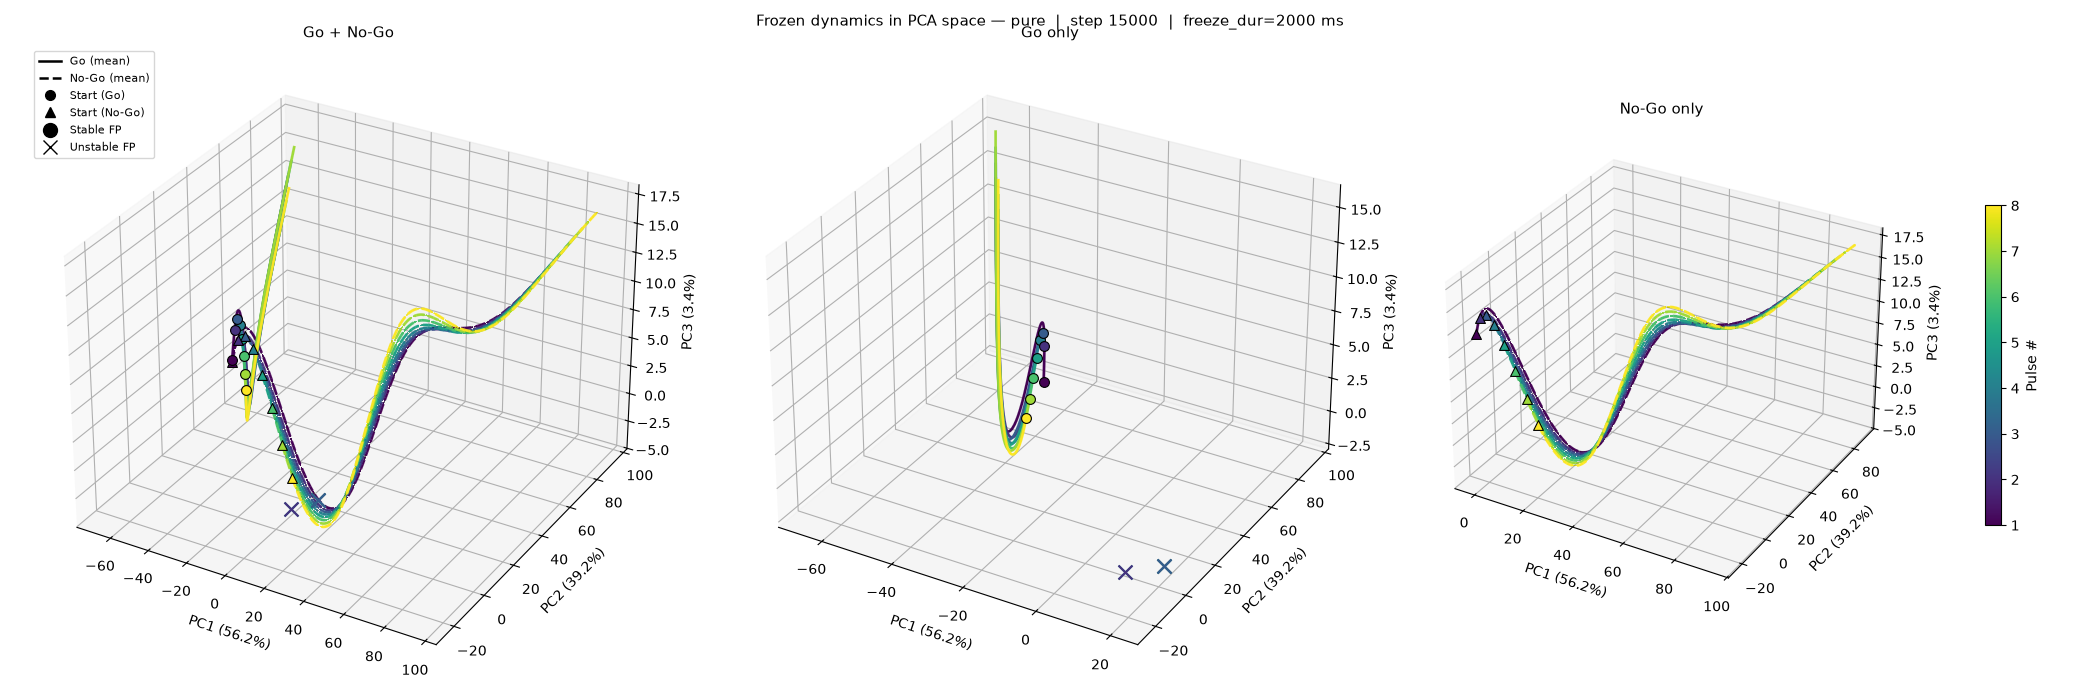

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_15000.png


In [22]:
# ── Autonomous trajectories in PCA space (3D) — all pulses + fixed points ─────
# (run_frozen, points, cmap, norm, n_auto already defined in the cell above)

fig = plt.figure(figsize=(21, 7))
axes = [fig.add_subplot(1, 3, i + 1, projection='3d') for i in range(3)]
titles = ['Go + No-Go', 'Go only', 'No-Go only']
show   = [('go', 'nogo'), ('go',), ('nogo',)]   # which conditions per panel

for phase, pulse_num in points:
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue

    color = cmap(norm(pulse_num))

    traj_go   = run_frozen(res['h_go'],   res['x_go'],   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], res['x_nogo'], n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]

    pc_go   = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   -1)
    pc_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, -1)
    mean_go   = pc_go.mean(axis=1)
    mean_nogo = pc_nogo.mean(axis=1)

    pc_by_cond   = {'go': pc_go,   'nogo': pc_nogo}
    mean_by_cond = {'go': mean_go, 'nogo': mean_nogo}
    ls_by_cond   = {'go': '-',     'nogo': '--'}
    mkr_by_cond  = {'go': 'o',     'nogo': '^'}

    # Fixed points per condition
    fp_by_cond = {}
    for cond in ('go', 'nogo'):
        if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
            fp_by_cond[cond] = pca.transform(res['conds'][cond]['h'])
            fp_by_cond[cond + '_stable'] = res['conds'][cond]['is_stable']

    for ax, conds in zip(axes, show):
        for cond in conds:
            pc   = pc_by_cond[cond]
            mean = mean_by_cond[cond]
            ls   = ls_by_cond[cond]
            mkr  = mkr_by_cond[cond]
            n_t  = pc.shape[1]

            # Individual trials
            for j in range(n_t):
                ax.plot(pc[:, j, 0], pc[:, j, 1], pc[:, j, 2],
                        color=color, alpha=0.04, lw=0.6, ls=ls)

            # Mean trajectory
            ax.plot(mean[:, 0], mean[:, 1], mean[:, 2],
                    color=color, lw=2.0, ls=ls, alpha=0.9)

            # Start point
            ax.scatter(*mean[0, :3], s=50, color=color, marker=mkr,
                       edgecolors='black', linewidths=0.8, depthshade=False, zorder=5)

            # Fixed points
            if cond in fp_by_cond:
                p      = fp_by_cond[cond]
                stable = fp_by_cond[cond + '_stable']
                for (px, py, pz, s) in zip(p[:, 0], p[:, 1], p[:, 2], stable):
                    if s:
                        ax.scatter(px, py, pz, s=140, marker='o', color=color,
                                   edgecolors='black', linewidths=1.2,
                                   depthshade=False, zorder=6)
                    else:
                        ax.scatter(px, py, pz, s=100, marker='x', color=color,
                                   depthshade=False, zorder=6)

for ax, title in zip(axes, titles):
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
    ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=4)
    ax.set_title(title, fontsize=11)

# Colorbar on last axis
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, ax=axes[-1], shrink=0.5, pad=0.12, label='Pulse #')
cb.set_ticks(range(1, len(points) + 1))

legend_handles = [
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go (mean)'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go (mean)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (Go)'),
    plt.Line2D([0], [0], color='k', marker='^', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (No-Go)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=10, markeredgecolor='black', label='Stable FP'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=10, label='Unstable FP'),
]
axes[0].legend(handles=legend_handles, fontsize=8, loc='upper left')

fig.suptitle(
    f'Frozen dynamics in PCA space — {task_type}  |  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_pca_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

In [29]:
# ── Frozen dynamics in PCA space — k3d (3 panels: all / go / nogo) ────────────
MAX_TRAJ_K3D = 16

panel_configs_k3d = [
    ('Go + No-Go', ('go', 'nogo'), 'frozen_pca_all'),
    ('Go only',    ('go',),        'frozen_pca_go'),
    ('No-Go only', ('nogo',),      'frozen_pca_nogo'),
]

for panel_title, conds_show, fname_base in panel_configs_k3d:
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', f'PC3 ({var_exp[2]:.1f}%)']

    for phase, pulse_num in points:
        key = phase_label(phase, pulse_num)
        res = results.get(key)
        if res is None:
            continue

        col = _k3d_color(cmap(norm(pulse_num)))

        traj_go   = run_frozen(res['h_go'],   res['x_go'],   n_auto)
        traj_nogo = run_frozen(res['h_nogo'], res['x_nogo'], n_auto)
        n_go_t    = traj_go.shape[1]
        n_nogo_t  = traj_nogo.shape[1]
        pc_go     = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   3)
        pc_nogo   = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, 3)
        mean_go   = pc_go.mean(axis=1)
        mean_nogo = pc_nogo.mean(axis=1)

        pc_by   = {'go': pc_go,   'nogo': pc_nogo}
        mean_by = {'go': mean_go, 'nogo': mean_nogo}

        fp_by = {}
        for cond in ('go', 'nogo'):
            if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
                fp_by[cond]             = pca.transform(res['conds'][cond]['h']).astype(np.float32)
                fp_by[cond + '_stable'] = res['conds'][cond]['is_stable']

        for cond in conds_show:
            pc   = pc_by[cond]
            mean = mean_by[cond]
            n_t  = pc.shape[1]
            lbl  = f'P{pulse_num} {cond}'

            # step = max(1, n_t // MAX_TRAJ_K3D)
            # for j in range(0, n_t, step):
            #     plot += k3d.line(pc[:, j, :].astype(np.float32),
            #                      color=col, width=0.005, opacity=0.15,
            #                      name=f'{lbl} trial')
            plot += k3d.line(mean.astype(np.float32),
                             color=col, width=0.04, opacity=0.9,
                             name=f'{lbl} mean')
            plot += k3d.points(mean[0:1].astype(np.float32), color=col,
                               point_size=3, shader='3d', name=f'{lbl} start')

            if cond in fp_by:
                pfp    = fp_by[cond]
                stable = fp_by[cond + '_stable']
                if stable.any():
                    plot += k3d.points(pfp[stable], color=col, point_size=2,
                                       shader='3d', name=f'Stable FP {lbl}')
                if (~stable).any():
                    plot += k3d.points(pfp[~stable], color=col, point_size=1,
                                       shader='flat', name=f'Unstable FP {lbl}')

    plot.display()
    out = out_dir / f'{fname_base}_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved: {out}')

Output()

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_all_15000.html


Output()

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_go_15000.html


Output()

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_nogo_15000.html


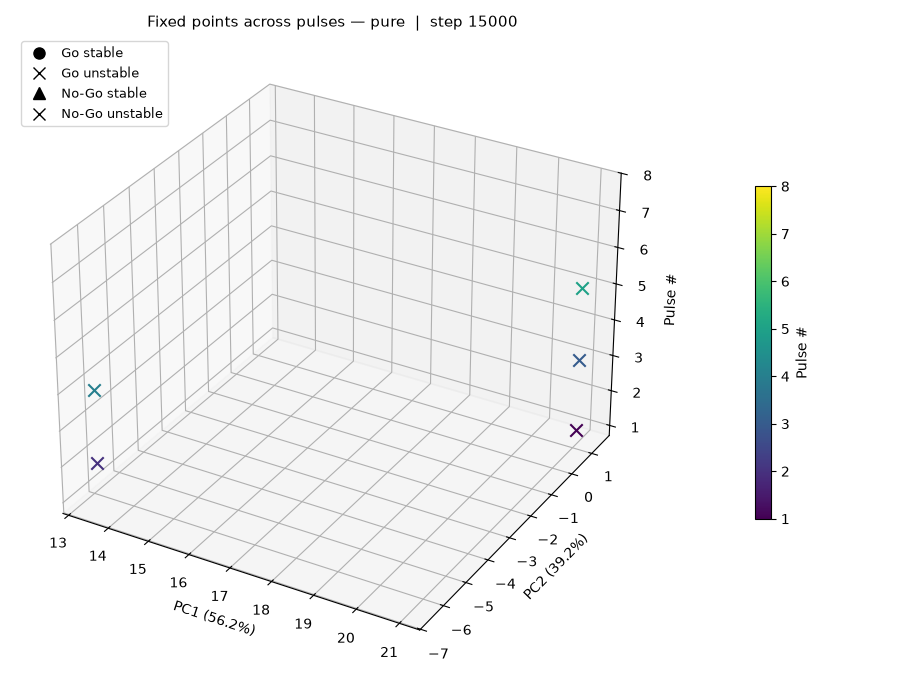

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fps_pulse_z_15000.png


In [24]:
# ── Fixed points: PC1 vs PC2 vs pulse number ─────────────────────────────────
# x = PC1, y = PC2, z = pulse number
# color = pulse number (viridis); shape = Go (circle) / No-Go (triangle)
# filled + black edge = stable, x = unstable

pulse_stops = [
    ('pulse_on', 1), ('pulse_on', 2), ('pulse_on', 3), ('pulse_on', 4),
    ('pulse_on', 5), ('pulse_on', 6), ('pulse_on', 7), ('pulse_on', 8),
]

cmap_fp = plt.cm.viridis
norm_fp = plt.Normalize(1, len(pulse_stops))
COND_MKR = {'go': 'o', 'nogo': '^'}

fig = plt.figure(figsize=(9, 7))
ax  = fig.add_subplot(111, projection='3d')

for phase, pulse_num in pulse_stops:
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue
    color = cmap_fp(norm_fp(pulse_num))

    for cond, mkr in COND_MKR.items():
        if cond not in res['conds'] or len(res['conds'][cond]['h']) == 0:
            continue
        fps    = pca.transform(res['conds'][cond]['h'])
        stable = res['conds'][cond]['is_stable']
        z      = np.full(len(fps), pulse_num)

        if stable.any():
            ax.scatter(fps[stable, 0], fps[stable, 1], z[stable],
                       s=120, marker=mkr, color=color,
                       edgecolors='black', linewidths=0.9,
                       depthshade=False)
        if (~stable).any():
            ax.scatter(fps[~stable, 0], fps[~stable, 1], z[~stable],
                       s=80, marker='x', color=color,
                       depthshade=False)

ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
ax.set_zlabel('Pulse #', labelpad=4)
ax.set_zticks(range(1, len(pulse_stops) + 1))

sm = plt.cm.ScalarMappable(cmap=cmap_fp, norm=norm_fp)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.12, label='Pulse #')
cb.set_ticks(range(1, len(pulse_stops) + 1))

legend_handles = [
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=8, markeredgecolor='black', label='Go stable'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=8, label='Go unstable'),
    plt.Line2D([0], [0], color='k', marker='^', linestyle='None',
               markersize=8, markeredgecolor='black', label='No-Go stable'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=8, label='No-Go unstable'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper left')

ax.set_title(
    f'Fixed points across pulses — {task_type}  |  step {ckpt["step"]}', fontsize=11)
plt.tight_layout()
out = out_dir / f'fps_pulse_z_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

In [32]:
# ── Fixed points: PC1 vs PC2 vs pulse# — k3d ─────────────────────────────────
pulse_stops_k3d = [
    ('pulse_on', 1), ('pulse_on', 2), ('pulse_on', 3), ('pulse_on', 4),
    ('pulse_on', 5), ('pulse_on', 6), ('pulse_on', 7), ('pulse_on', 8),
]
cmap_fp_k3d = plt.cm.viridis
norm_fp_k3d = plt.Normalize(1, len(pulse_stops_k3d))

plot = k3d.plot(background_color=0xffffff, height=600)
plot.axes = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', 'Pulse #']

for phase, pulse_num in pulse_stops_k3d:
    key = phase_label(phase, pulse_num)
    res = results.get(key)
    if res is None:
        continue
    col = _k3d_color(cmap_fp_k3d(norm_fp_k3d(pulse_num)))

    for cond, sz_stable, sz_unstable in [('go', 0.3, 0.2), ('nogo', 0.15, 0.05)]:
        if cond not in res['conds'] or len(res['conds'][cond]['h']) == 0:
            continue
        fps    = pca.transform(res['conds'][cond]['h'])
        stable = res['conds'][cond]['is_stable']
        z      = np.full(len(fps), float(pulse_num))
        pts3d  = np.column_stack([fps[:, 0], fps[:, 1], z]).astype(np.float32)

        if stable.any():
            plot += k3d.points(pts3d[stable], color=col, point_size=sz_stable,
                               shader='3d', name=f'Stable {cond} P{pulse_num}')
        if (~stable).any():
            plot += k3d.points(pts3d[~stable], color=col, point_size=sz_unstable,
                               shader='flat', name=f'Unstable {cond} P{pulse_num}')

plot.display()
out = out_dir / f'fps_pulse_z_{ckpt["step"]}.html'
with open(out, 'w') as f:
    f.write(plot.get_snapshot())
print(f'Saved: {out}')

Output()

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fps_pulse_z_15000.html


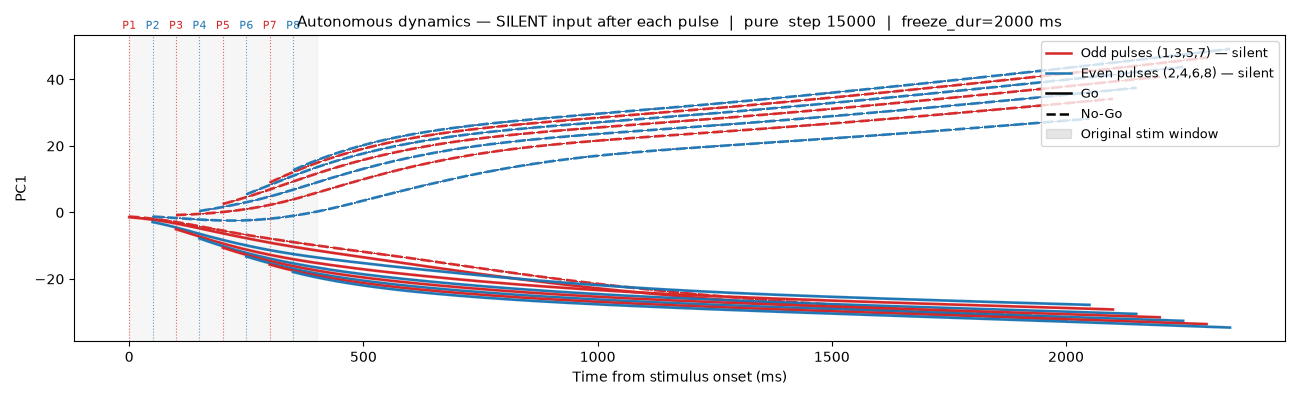

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_traj_15000.png


In [26]:
# ── Autonomous trajectories — SILENT input (stimulus off after each pulse) ─────
# Same start points as the pulse-frozen trajectories above, but the frozen input
# has all frequency channels zeroed:
#   freq channels  = 0   (silence)
#   fixation       = 1   if pulse_num == 1 (stim just started)
#                    0   for later pulses (fully within stim period)
#   context        = preserved (same as during stimulus)
# Shows where the network flows if the stimulus is suddenly cut at pulse N onset.

n_freq_chan = trial.n_freq

def make_silent_x(x_with_stim, pulse_num):
    """Return input with freq channels zeroed; fixation=1 for pulse 1, else 0."""
    x = x_with_stim.copy()
    x[:n_freq_chan] = 0.0
    x[n_freq_chan]  = 1.0 if pulse_num == 1 else 0.0   # fixation
    # context channels (n_freq_chan+1 onward) unchanged
    return x

ODD_COLOR_S  = 'tab:red'
EVEN_COLOR_S = 'tab:blue'

fig, ax = plt.subplots(figsize=(13, 4))
xform = ax.get_xaxis_transform()

for pidx, (phase, pulse_num) in enumerate(points):
    key = phase_label(phase, pulse_num)
    res = results.get(key)
    if res is None:
        continue
    color = ODD_COLOR_S if pulse_num % 2 == 1 else EVEN_COLOR_S
    t_step       = res['t_step']
    t_offset_ms  = (t_step - stim_on) * dt
    t_axis_local = t_offset_ms + np.arange(n_auto + 1) * dt

    x_off_go   = make_silent_x(res['x_go'],   pulse_num)
    x_off_nogo = make_silent_x(res['x_nogo'], pulse_num)
    traj_go   = run_frozen(res['h_go'],   x_off_go,   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], x_off_nogo, n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]
    pc1_go   = pca.transform(traj_go.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_go_t)
    pc1_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_nogo_t)

    for j in range(n_go_t):
        ax.plot(t_axis_local, pc1_go[:, j],   color=color, alpha=0.03, lw=0.6, ls='-')
    for j in range(n_nogo_t):
        ax.plot(t_axis_local, pc1_nogo[:, j], color=color, alpha=0.03, lw=0.6, ls='--')
    ax.plot(t_axis_local, pc1_go.mean(1),   color=color, lw=2.0, ls='-',  alpha=0.9)
    ax.plot(t_axis_local, pc1_nogo.mean(1), color=color, lw=2.0, ls='--', alpha=0.9)
    ax.axvline(t_offset_ms, color=color, lw=0.8, ls=':', alpha=0.7)
    ax.text(t_offset_ms, 1.02, f'P{pulse_num}', fontsize=8,
            ha='center', color=color, transform=xform)

ax.axvspan(0, (stim_off - stim_on) * dt, alpha=0.07, color='gray')
ax.set_xlabel('Time from stimulus onset (ms)')
ax.set_ylabel('PC1')

legend_handles = [
    plt.Line2D([0], [0], color=ODD_COLOR_S,  lw=1.8, label='Odd pulses (1,3,5,7) — silent'),
    plt.Line2D([0], [0], color=EVEN_COLOR_S, lw=1.8, label='Even pulses (2,4,6,8) — silent'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go'),
    mpatches.Patch(color='gray', alpha=0.2, label='Original stim window'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper right')
ax.set_title(
    f'Autonomous dynamics — SILENT input after each pulse  |  {task_type}  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_silent_traj_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

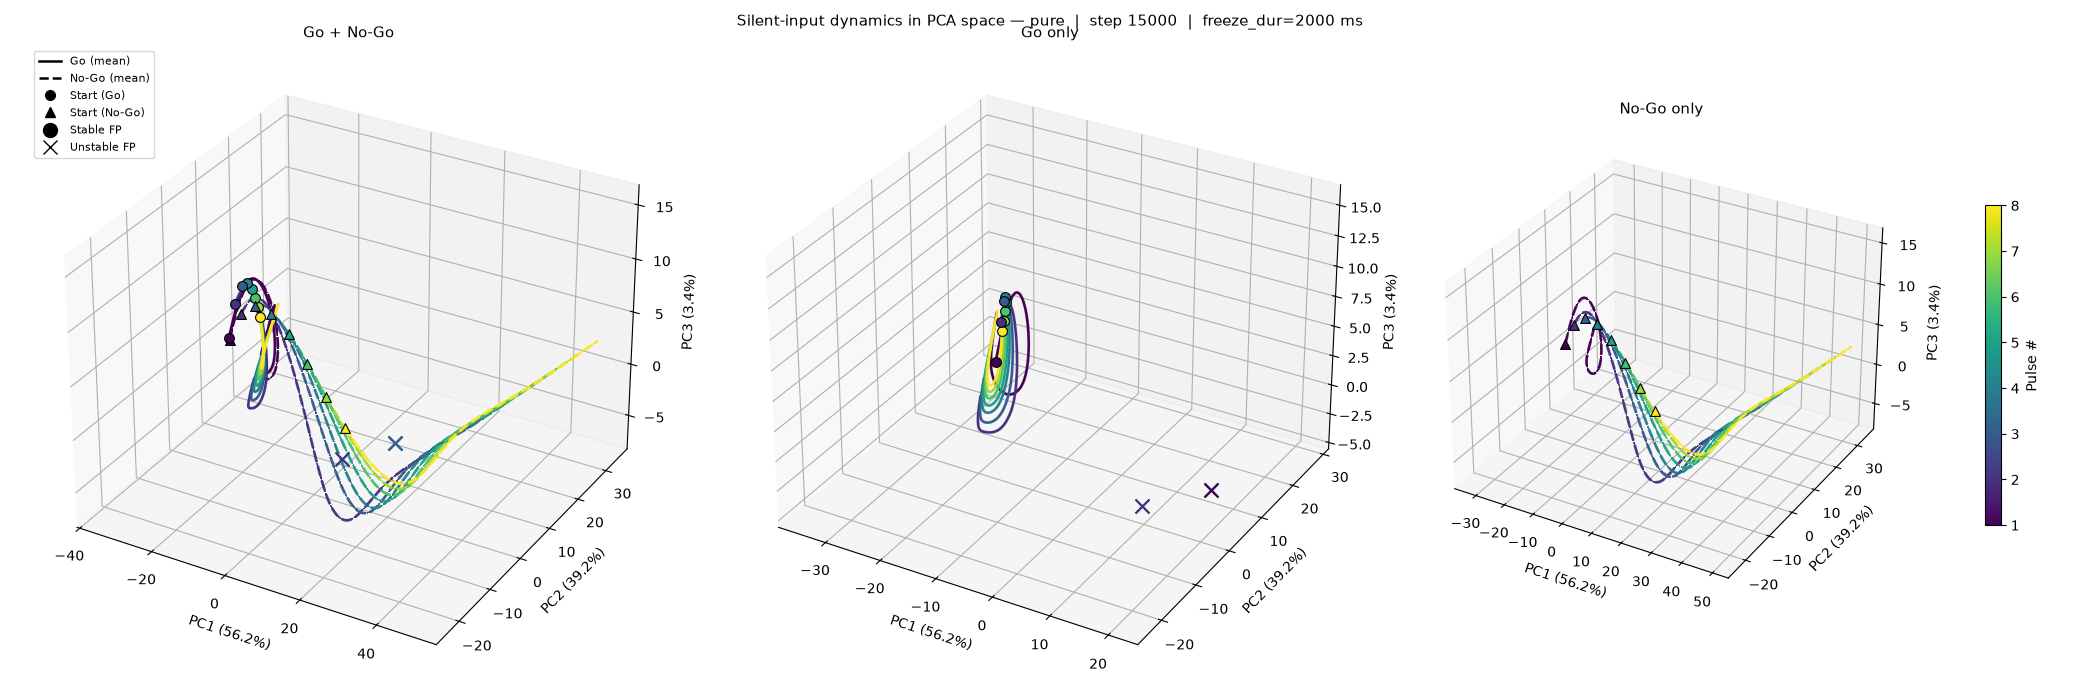

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_15000.png


In [27]:
# ── Silent-input frozen dynamics in PCA space (3D) — 3 subplots ───────────────
# Same as b8b7f5c3 but using make_silent_x (freq=0, context preserved).

fig = plt.figure(figsize=(21, 7))
axes_s = [fig.add_subplot(1, 3, i + 1, projection='3d') for i in range(3)]
titles_s = ['Go + No-Go', 'Go only', 'No-Go only']
show_s   = [('go', 'nogo'), ('go',), ('nogo',)]

for phase, pulse_num in points:
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue

    color = cmap(norm(pulse_num))
    x_off_go   = make_silent_x(res['x_go'],   pulse_num)
    x_off_nogo = make_silent_x(res['x_nogo'], pulse_num)

    traj_go   = run_frozen(res['h_go'],   x_off_go,   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], x_off_nogo, n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]
    pc_go   = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   -1)
    pc_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, -1)
    mean_go   = pc_go.mean(axis=1)
    mean_nogo = pc_nogo.mean(axis=1)

    pc_by_cond_s   = {'go': pc_go,   'nogo': pc_nogo}
    mean_by_cond_s = {'go': mean_go, 'nogo': mean_nogo}
    ls_by_cond_s   = {'go': '-',     'nogo': '--'}
    mkr_by_cond_s  = {'go': 'o',     'nogo': '^'}

    fp_by_cond_s = {}
    for cond in ('go', 'nogo'):
        if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
            fp_by_cond_s[cond]           = pca.transform(res['conds'][cond]['h'])
            fp_by_cond_s[cond + '_stable'] = res['conds'][cond]['is_stable']

    for ax, conds in zip(axes_s, show_s):
        for cond in conds:
            pc   = pc_by_cond_s[cond]
            mean = mean_by_cond_s[cond]
            ls   = ls_by_cond_s[cond]
            mkr  = mkr_by_cond_s[cond]
            n_t  = pc.shape[1]

            for j in range(n_t):
                ax.plot(pc[:, j, 0], pc[:, j, 1], pc[:, j, 2],
                        color=color, alpha=0.04, lw=0.6, ls=ls)
            ax.plot(mean[:, 0], mean[:, 1], mean[:, 2],
                    color=color, lw=2.0, ls=ls, alpha=0.9)
            ax.scatter(*mean[0, :3], s=50, color=color, marker=mkr,
                       edgecolors='black', linewidths=0.8, depthshade=False, zorder=5)

            if cond in fp_by_cond_s:
                p      = fp_by_cond_s[cond]
                stable = fp_by_cond_s[cond + '_stable']
                for (px, py, pz, s) in zip(p[:, 0], p[:, 1], p[:, 2], stable):
                    if s:
                        ax.scatter(px, py, pz, s=140, marker='o', color=color,
                                   edgecolors='black', linewidths=1.2,
                                   depthshade=False, zorder=6)
                    else:
                        ax.scatter(px, py, pz, s=100, marker='x', color=color,
                                   depthshade=False, zorder=6)

for ax, title in zip(axes_s, titles_s):
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
    ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=4)   
    ax.set_title(title, fontsize=11)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, ax=axes_s[-1], shrink=0.5, pad=0.12, label='Pulse #')
cb.set_ticks(range(1, len(points) + 1))

legend_handles = [
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go (mean)'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go (mean)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (Go)'),
    plt.Line2D([0], [0], color='k', marker='^', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (No-Go)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=10, markeredgecolor='black', label='Stable FP'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=10, label='Unstable FP'),
]
axes_s[0].legend(handles=legend_handles, fontsize=8, loc='upper left')

fig.suptitle(
    f'Silent-input dynamics in PCA space — {task_type}  |  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_silent_pca_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

In [28]:
# ── Silent-input dynamics in PCA space — k3d (3 panels: all / go / nogo) ──────
panel_configs_s_k3d = [
    ('Go + No-Go', ('go', 'nogo'), 'frozen_silent_pca_all'),
    ('Go only',    ('go',),        'frozen_silent_pca_go'),
    ('No-Go only', ('nogo',),      'frozen_silent_pca_nogo'),
]

for panel_title, conds_show, fname_base in panel_configs_s_k3d:
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', f'PC3 ({var_exp[2]:.1f}%)']

    for phase, pulse_num in points:
        key = phase_label(phase, pulse_num)
        res = results.get(key)
        if res is None:
            continue

        col        = _k3d_color(cmap(norm(pulse_num)))
        x_off_go   = make_silent_x(res['x_go'],   pulse_num)
        x_off_nogo = make_silent_x(res['x_nogo'], pulse_num)
        traj_go    = run_frozen(res['h_go'],   x_off_go,   n_auto)
        traj_nogo  = run_frozen(res['h_nogo'], x_off_nogo, n_auto)
        n_go_t     = traj_go.shape[1]
        n_nogo_t   = traj_nogo.shape[1]
        pc_go      = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   3)
        pc_nogo    = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, 3)
        mean_go    = pc_go.mean(axis=1)
        mean_nogo  = pc_nogo.mean(axis=1)

        pc_by   = {'go': pc_go,   'nogo': pc_nogo}
        mean_by = {'go': mean_go, 'nogo': mean_nogo}

        fp_by = {}
        for cond in ('go', 'nogo'):
            if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
                fp_by[cond]             = pca.transform(res['conds'][cond]['h']).astype(np.float32)
                fp_by[cond + '_stable'] = res['conds'][cond]['is_stable']

        for cond in conds_show:
            pc   = pc_by[cond]
            mean = mean_by[cond]
            n_t  = pc.shape[1]
            lbl  = f'P{pulse_num} {cond}'

            step = max(1, n_t // MAX_TRAJ_K3D)
            for j in range(0, n_t, step):
                plot += k3d.line(pc[:, j, :].astype(np.float32),
                                 color=col, width=0.005, opacity=0.15,
                                 name=f'{lbl} trial')
            plot += k3d.line(mean.astype(np.float32),
                             color=col, width=0.04, opacity=0.9,
                             name=f'{lbl} mean')
            plot += k3d.points(mean[0:1].astype(np.float32), color=col,
                               point_size=35, shader='3d', name=f'{lbl} start')

            if cond in fp_by:
                pfp    = fp_by[cond]
                stable = fp_by[cond + '_stable']
                if stable.any():
                    plot += k3d.points(pfp[stable], color=col, point_size=45,
                                       shader='3d', name=f'Stable FP {lbl}')
                if (~stable).any():
                    plot += k3d.points(pfp[~stable], color=col, point_size=30,
                                       shader='flat', name=f'Unstable FP {lbl}')

    plot.display()
    out = out_dir / f'{fname_base}_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved: {out}')

Output()

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_all_15000.html


Output()

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_go_15000.html


Output()

Saved: results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_nogo_15000.html
